<a href="https://colab.research.google.com/github/igorferreira083/am-turma5/blob/main/RedesNeurais_aula1027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline Conector de Drive e Pre-Load de Dados [Credit]

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pickle
with open('/content/drive/MyDrive/am-t6/credit.pkl', 'rb') as f:
    X_credit_train, y_credit_train, X_credit_test, y_credit_test = pickle.load(f)

Provedor de Testes [25%]

In [3]:
X_credit_test.shape, y_credit_test.shape

((500, 3), (500,))

Provedor de Treino [75%]

In [4]:
X_credit_train.shape, y_credit_train.shape

((1500, 3), (1500,))

# # Pipeline Redes Neurais [Credit]

In [5]:
parametros = {
    'activation': ['relu', 'logistic', 'tanh'],
    'solver': ['adam', 'sgd'],
    'batch_size': [10, 56]
}

In [6]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [7]:
grid_search = GridSearchCV(
    estimator=MLPClassifier(),
    param_grid=parametros
)

grid_search.fit(X_credit_train, y_credit_train)

melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import DecisionBoundaryDisplay

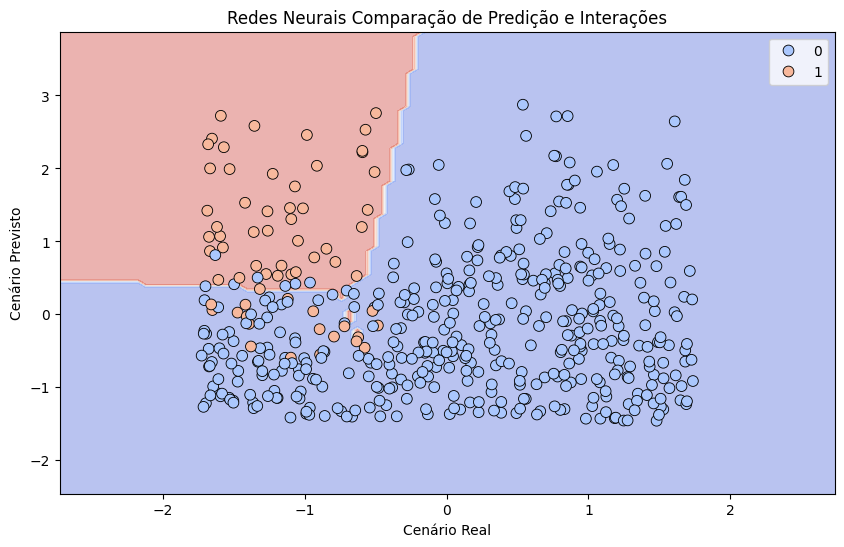

In [10]:
x_2d = X_credit_test[:, 1:3] # Cenário real da construção do treinamento
y_2d = y_credit_test # Respostas ao cenário real

rna_2d = MLPClassifier(**grid_search.best_params_, max_iter=1000, random_state=42)
rna_2d.fit(x_2d, y_credit_test) # Cenário sintético da Rede Neural

fig, ax =plt.subplots(figsize=(10, 6)) # Montagem dos dois cenários

DecisionBoundaryDisplay.from_estimator(
    rna_2d,
    x_2d,
    cmap="coolwarm",
    alpha=0.4,
    ax=ax,
    response_method="predict"
)

sns.scatterplot(
    x=x_2d[:, 0],
    y=x_2d[:, 1],
hue=y_credit_test,
    palette="coolwarm",
    edgecolor="black",
    s=60,
    ax=ax
)
plt.title("Redes Neurais Comparação de Predição e Interações")
plt.xlabel("Cenário Real")
plt.ylabel("Cenário Previsto")
plt.show()